# 02 Evaluation against buy-and-hold

**Question: does volatility timing beat buy-and-hold?** Every managed portfolio built in
`01_build_portfolios.ipynb` is compared with the equal-weighted buy-and-hold (BH) benchmark, for
the cyclical bucket and for each ETF on its own, under both specifications of σ̄².

The last section is the **expanding-σ̄² extension**: it separates what the forecast adds from the
re-levering that comes from the moving reference.

Comparisons between models, which answer the research question directly, are in
`03_eval_model_comparisons.ipynb`.

## Setup

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from portfolio_utils import (
    CONTROL, PORTFOLIO_DIR, EVAL_DIR, load_portfolios,
    performance_row, evaluate_bucket, alpha_regression, alpha_vs_bh_and_control,
    per_etf_table, pct_capped, pct_capped_pooled,
)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.4f}".format)

### Load the saved portfolios

The models, specifications and cap come from `results/portfolios/run_info.json`, so this notebook
always matches the latest run of `01_build_portfolios.ipynb`.

In [2]:
run_info = json.loads((PORTFOLIO_DIR / "run_info.json").read_text())
MODELS, SPECS, K_CAP = run_info["variants"], run_info["specs"], run_info["k_cap"]

portfolios = {}
for spec in SPECS:
    portfolios[spec], xret = load_portfolios(spec)
    assert set(MODELS) <= set(portfolios[spec]), f"{spec}: saved models do not match run_info"
TICKERS = list(xret.columns)
bh = xret.mean(axis=1)

print("Models:", MODELS)
print("Specifications:", SPECS)
print(f"Out-of-sample window: {run_info['oos_window'][0]} to {run_info['oos_window'][1]}"
      f" ({len(xret)} months)")

Models: ['garch', 'garch_midas_baa10y', 'ols_1m', 'en_full_macro', 'en_no_macro', 'en_no_vix', 'xgb_full_macro', 'xgb_no_macro', 'xgb_no_vix', 'xgb_vix_only']
Specifications: ['fixed', 'expanding']
Out-of-sample window: 2008-03 to 2025-12 (214 months)


## Evaluation measures

The evaluation functions are in `portfolio_utils.py`:

- **Performance** (`performance_row`): annualised mean and volatility of monthly excess returns,
  annualised Sharpe ratio, maximum drawdown of the cumulative excess-return series, and average
  monthly turnover mean_t Σᵢ |wᵢ,ₜ − wᵢ,ₜ₋₁| over the weight held in each ETF. Buy-and-hold holds
  fixed weights, so its turnover is 0 by this measure (it ignores rebalancing after prices drift).
- **Ledoit & Wolf (2008)** (`ledoit_wolf_sharpe_test`): tests H₀: SR(managed) = SR(BH) with the
  studentised circular block bootstrap. The standard error of the Sharpe-ratio difference uses a
  HAC (Bartlett) estimator in the original sample and the block-based estimator in each bootstrap
  sample. The p-value is the share of bootstrap |t*| (centred on the sample difference) at least as
  large as the observed |t|. Sharpe ratios are tested on monthly data and reported annualised.
- **Alpha** (`alpha_regression`): f^σ_t = α + β · BH_t + εₜ with Newey-West HAC standard errors
  (lag = ⌊4(T/100)^{2/9}⌋). α is reported annualised (× 12).
- **% at the cap** (`pct_capped_pooled`): the share of ETF-months in which the base weight is at
  the cap k = 3.

## Cyclical bucket: every model vs buy-and-hold

One table per specification, with one row per model plus buy-and-hold: performance, the
Ledoit-Wolf test of SR(model) − SR(BH), the alpha regression on BH and the % of months at the cap.

In [3]:
bh_weights = pd.DataFrame(1 / len(TICKERS), index=xret.index, columns=TICKERS)

bucket = {}
for spec in SPECS:
    res = portfolios[spec]
    tbl = pd.DataFrame(
        {"BH_Cyclical": performance_row(bh, bh_weights)}
        | {m: evaluate_bucket(res[m], bh) for m in MODELS}
    ).T
    tbl["pct_capped"] = pd.Series({m: pct_capped_pooled(res[m]["weights_base"], K_CAP) for m in MODELS})
    bucket[spec] = tbl.rename_axis("portfolio")

## fixed sigma2_bar
bucket["fixed"]

,ann_mean,ann_vol,ann_sharpe,max_drawdown,avg_turnover,c,SR_diff_vs_BH,LW_t,LW_p,alpha_annual,alpha_t,alpha_p,beta_BH,R2,pct_capped
portfolio,,,,,,,,,,,,,,,
BH_Cyclical,0.0922,0.1938,0.4760,-0.5552,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
garch,0.0962,0.1938,0.4966,-0.4579,0.4098,1.3801,0.0207,0.1181,0.9124,0.0245,0.7867,0.4315,0.7778,0.6050,4.3925
garch_midas_baa10y,0.0957,0.1938,0.4938,-0.4615,0.4119,1.3745,0.0178,0.1011,0.9272,0.0241,0.7686,0.4421,0.7759,0.6021,4.5794
ols_1m,0.0879,0.1938,0.4535,-0.5270,0.4990,1.4532,-0.0225,-0.1251,0.9138,0.0163,0.5050,0.6136,0.7766,0.6031,5.4206
en_full_macro,0.0773,0.1938,0.3990,-0.5215,0.3375,1.4994,-0.0772,-0.4352,0.6907,0.0061,0.1944,0.8459,0.7718,0.5957,3.2710
en_no_macro,0.0879,0.1938,0.4536,-0.5271,0.4987,1.4540,-0.0224,-0.1249,0.9138,0.0163,0.5048,0.6137,0.7768,0.6034,5.3271
en_no_vix,0.0806,0.1938,0.4161,-0.5574,0.3686,1.4524,-0.0601,-0.3329,0.7636,0.0079,0.2420,0.8088,0.7888,0.6222,4.7664
xgb_full_macro,0.0654,0.1938,0.3375,-0.5332,0.3320,1.4799,-0.1388,-0.9065,0.4043,-0.0091,-0.3190,0.7497,0.8074,0.6519,1.9626
xgb_no_macro,0.0830,0.1938,0.4284,-0.5072,0.4231,1.4587,-0.0477,-0.3284,0.7688,0.0061,0.2331,0.8157,0.8338,0.6952,1.4953


In [4]:
## expanding sigma2_bar
bucket["expanding"]

,ann_mean,ann_vol,ann_sharpe,max_drawdown,avg_turnover,c,SR_diff_vs_BH,LW_t,LW_p,alpha_annual,alpha_t,alpha_p,beta_BH,R2,pct_capped
portfolio,,,,,,,,,,,,,,,
BH_Cyclical,0.0922,0.1938,0.4760,-0.5552,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
garch,0.1178,0.1938,0.6079,-0.3649,0.2138,0.8525,0.1322,0.8095,0.4893,0.0408,1.3807,0.1674,0.8351,0.6973,45.5140
garch_midas_baa10y,0.1178,0.1938,0.6079,-0.3648,0.2145,0.8518,0.1322,0.8035,0.4919,0.0409,1.3714,0.1703,0.8340,0.6956,45.9813
ols_1m,0.1148,0.1938,0.5926,-0.4291,0.2815,0.9001,0.1169,0.7153,0.5317,0.0372,1.2527,0.2103,0.8417,0.7084,36.7290
en_full_macro,0.1045,0.1938,0.5391,-0.4231,0.2114,0.9133,0.0633,0.3912,0.7247,0.0284,0.9824,0.3259,0.8250,0.6806,36.0748
en_no_macro,0.1148,0.1938,0.5926,-0.4292,0.2815,0.9002,0.1169,0.7154,0.5317,0.0372,1.2526,0.2103,0.8418,0.7085,36.7290
en_no_vix,0.1065,0.1938,0.5497,-0.4536,0.2222,0.8864,0.0739,0.4488,0.6795,0.0283,0.9441,0.3451,0.8484,0.7198,33.2710
xgb_full_macro,0.0892,0.1938,0.4601,-0.4443,0.2344,0.8868,-0.0159,-0.1137,0.9210,0.0105,0.4130,0.6796,0.8528,0.7272,35.5140
xgb_no_macro,0.1097,0.1938,0.5660,-0.4238,0.2698,0.8617,0.0902,0.6675,0.5505,0.0288,1.1950,0.2321,0.8764,0.7681,39.8131


In [5]:
# Side by side: the main statistics under each specification
pd.concat({spec: bucket[spec][["ann_sharpe", "SR_diff_vs_BH", "LW_p", "alpha_annual", "alpha_t",
                               "pct_capped"]]
           for spec in SPECS}, axis=1)

fixed                                                       expanding                                            \
                   ann_sharpe SR_diff_vs_BH   LW_p alpha_annual alpha_t pct_capped ann_sharpe SR_diff_vs_BH   LW_p alpha_annual alpha_t   
portfolio                                                                                                                                 
BH_Cyclical            0.4760           NaN    NaN          NaN     NaN        NaN     0.4760           NaN    NaN          NaN     NaN   
garch                  0.4966        0.0207 0.9124       0.0245  0.7867     4.3925     0.6079        0.1322 0.4893       0.0408  1.3807   
garch_midas_baa10y     0.4938        0.0178 0.9272       0.0241  0.7686     4.5794     0.6079        0.1322 0.4919       0.0409  1.3714   
ols_1m                 0.4535       -0.0225 0.9138       0.0163  0.5050     5.4206     0.5926        0.1169 0.5317       0.0372  1.2527   
en_full_macro          0.3990       -0.0772 0.6907       0.0061  0.1944     3.2710     0.5391        0.0633 0.7247       0.0284  0.9824   
en_no_macro            0.4536       -0.0224 0.9138       0.0163  0.5048     5.3271     0.5926        0.1169 0.5317       0.0372  1.2526   
en_no_vix              0.4161       -0.0601 0.7636       0.0079  0.2420     4.7664     0.5497        0.0739 0.6795       0.0283  0.9441   
xgb_full_macro         0.3375       -0.1388 0.4043      -0.0091 -0.3190     1.9626     0.4601       -0.0159 0.9210       0.0105  0.4130   
xgb_no_macro           0.4284       -0.0477 0.7688       0.0061  0.2331     1.4953     0.5660        0.0902 0.5505       0.0288  1.1950   
xgb_no_vix             0.3982       -0.0779 0.6523       0.0008  0.0259     1.1215     0.5110        0.0351 0.8244       0.0194  0.7248   
xgb_vix_only           0.4040       -0.0721 0.6647       0.0041  0.1438     2.8037     0.4927        0.0167 0.9160       0.0163  0.6577   

                               
                   pct_capped  
portfolio                      
BH_Cyclical               NaN  
garch                 45.5140  
garch_midas_baa10y    45.9813  
ols_1m                36.7290  
en_full_macro         36.0748  
en_no_macro           36.7290  
en_no_vix             33.2710  
xgb_full_macro        35.5140  
xgb_no_macro          39.8131  
xgb_no_vix            31.3084  
xgb_vix_only          41.1215

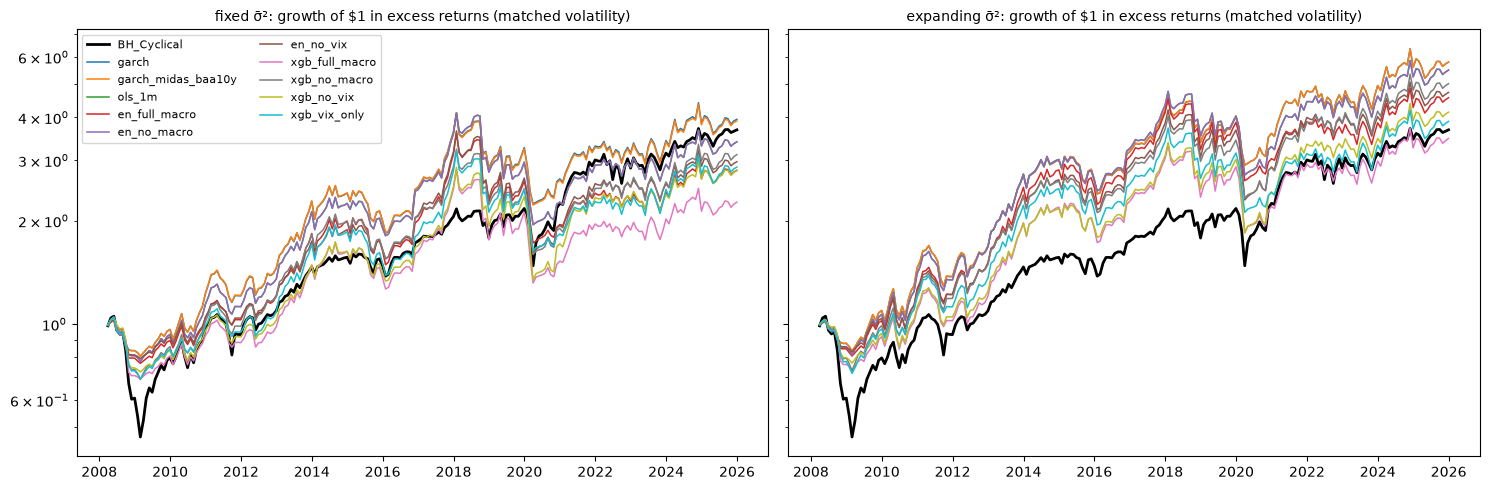

In [6]:
fig, axes = plt.subplots(1, len(SPECS), figsize=(15, 5), sharey=True, squeeze=False)
for ax, spec in zip(axes.flat, SPECS):
    returns = pd.DataFrame({"BH_Cyclical": bh} | {m: portfolios[spec][m]["managed"] for m in MODELS})
    for name, r in returns.items():
        style = dict(color="black", linewidth=2) if name == "BH_Cyclical" else dict(linewidth=1.1)
        ax.plot(r.index, (1 + r).cumprod(), label=name, **style)
    ax.set_yscale("log")
    ax.set_title(f"{spec} σ̄²: growth of $1 in excess returns (matched volatility)", fontsize=10)
axes.flat[0].legend(ncol=2, fontsize=8)
fig.tight_layout()
plt.show()

## Per-ETF portfolios: every model vs that ETF's buy-and-hold

For each model, each ETF's managed series positionᵢ,ₜ₊₁ is compared with that ETF's own
buy-and-hold excess return. It is rescaled by cᵢ = σ(rᵢ − rf) / σ(positionᵢ) over the
out-of-sample period, so each pair has matched volatility. cᵢ does not affect the Sharpe ratio,
the Ledoit-Wolf test or the alpha t-statistic.

In [7]:
per_etf = {}
for spec in SPECS:
    res = portfolios[spec]
    per_etf[spec] = pd.concat(
        {m: per_etf_table(res[m], xret).assign(pct_capped=pct_capped(res[m]["weights_base"], K_CAP))
         for m in MODELS},
        names=["model", "ETF"])

## fixed sigma2_bar
per_etf["fixed"]

c_i  SR_managed  SR_BH  SR_diff   LW_p  alpha_annual  alpha_t  maxDD_managed  maxDD_BH  avg_turnover  pct_capped
model              ETF                                                                                                                    
garch              XLB 1.1983      0.2328 0.3612  -0.1287 0.4663       -0.0128  -0.4345        -0.4294   -0.5589        0.3328      4.2056
                   XLE 1.1002      0.1202 0.2366  -0.1167 0.4135       -0.0183  -0.4888        -0.8331   -0.6597        0.3211      9.8131
                   XLF 1.3907      0.5956 0.3632   0.2330 0.3971        0.0754   1.7644        -0.3357   -0.7083        0.4943      5.6075
                   XLI 1.6549      0.6061 0.5502   0.0561 0.7624        0.0314   1.0395        -0.3269   -0.5550        0.4005      0.0000
                   XLY 1.4370      0.8068 0.6715   0.1356 0.4879        0.0603   1.8669        -0.3096   -0.4542        0.4565      2.3364
garch_midas_baa10y XLB 1.1968      0.2318 0.3612  -0.1297 0.4675       -0.0129  -0.4335        -0.4320   -0.5589        0.3351      4.2056
                   XLE 1.0947      0.1153 0.2366  -0.1215 0.3955       -0.0194  -0.5181        -0.8354   -0.6597        0.3230     10.7477
                   XLF 1.3870      0.5961 0.3632   0.2335 0.3989        0.0756   1.7596        -0.3354   -0.7083        0.4954      5.6075
                   XLI 1.6437      0.5983 0.5502   0.0483 0.7948        0.0301   0.9822        -0.3324   -0.5550        0.4024      0.0000
                   XLY 1.4281      0.8066 0.6715   0.1354 0.4947        0.0606   1.8584        -0.3117   -0.4542        0.4592      2.3364
ols_1m             XLB 1.2617      0.1987 0.3612  -0.1629 0.3531       -0.0197  -0.6469        -0.5220   -0.5589        0.4305      8.4112
                   XLE 1.2170      0.1006 0.2366  -0.1363 0.3233       -0.0244  -0.6599        -0.8454   -0.6597        0.3855      7.9439
                   XLF 1.5204      0.5155 0.3632   0.1527 0.5659        0.0596   1.3400        -0.4500   -0.7083        0.6036      4.2056
                   XLI 1.6716      0.5343 0.5502  -0.0159 0.9282        0.0186   0.5912        -0.4372   -0.5550        0.5109      1.4019
                   XLY 1.4427      0.7917 0.6715   0.1205 0.5591        0.0595   1.7304        -0.4003   -0.4542        0.5140      5.1402
en_full_macro      XLB 1.2638      0.1277 0.3612  -0.2340 0.1812       -0.0342  -1.1176        -0.4875   -0.5589        0.3026      5.6075
                   XLE 1.3941      0.0813 0.2366  -0.1557 0.2178       -0.0307  -0.9041        -0.8429   -0.6597        0.3281      3.2710
                   XLF 1.5388      0.4689 0.3632   0.1060 0.6877        0.0502   1.1456        -0.4701   -0.7083        0.3960      4.6729
                   XLI 1.6276      0.4608 0.5502  -0.0895 0.6403        0.0051   0.1587        -0.4442   -0.5550        0.2582      0.0000
                   XLY 1.4800      0.7270 0.6715   0.0556 0.7734        0.0466   1.4176        -0.3690   -0.4542        0.3475      2.8037
en_no_macro        XLB 1.2624      0.1989 0.3612  -0.1627 0.3535       -0.0197  -0.6464        -0.5220   -0.5589        0.4303      8.4112
                   XLE 1.2173      0.1006 0.2366  -0.1363 0.3231       -0.0244  -0.6601        -0.8453   -0.6597        0.3854      7.4766
                   XLF 1.5219      0.5156 0.3632   0.1528 0.5655        0.0596   1.3406        -0.4498   -0.7083        0.6033      4.2056
                   XLI 1.6725      0.5343 0.5502  -0.0160 0.9280        0.0186   0.5903        -0.4372   -0.5550        0.5105      1.4019
                   XLY 1.4434      0.7918 0.6715   0.1206 0.5591        0.0595   1.7305        -0.4001   -0.4542        0.5136      5.1402
en_no_vix          XLB 1.2449      0.1739 0.3612  -0.1877 0.3001       -0.0251  -0.8018        -0.5450   -0.5589        0.3279      8.8785
                   XLE 1.3859      0.0875 0.2366  -0.1494 0.2308       -0.0297  -0.8901        -0.8405   -0.6597        0.3323      3.

In [8]:
## expanding sigma2_bar
per_etf["expanding"]

c_i  SR_managed  SR_BH  SR_diff   LW_p  alpha_annual  alpha_t  maxDD_managed  maxDD_BH  avg_turnover  pct_capped
model              ETF                                                                                                                    
garch              XLB 0.8194      0.3013 0.3612  -0.0601 0.7199       -0.0014  -0.0472        -0.3645   -0.5589        0.2256     38.3178
                   XLE 0.8161      0.2257 0.2366  -0.0109 0.9370        0.0070   0.2144        -0.7687   -0.6597        0.1865     43.9252
                   XLF 0.7380      0.6324 0.3632   0.2698 0.3223        0.0760   1.8850        -0.3417   -0.7083        0.1170     71.4953
                   XLI 0.8678      0.6575 0.5502   0.1076 0.5629        0.0387   1.2636        -0.2952   -0.5550        0.2571     35.9813
                   XLY 0.8970      0.9054 0.6715   0.2344 0.2032        0.0729   2.4572        -0.2339   -0.4542        0.2649     37.8505
garch_midas_baa10y XLB 0.8191      0.3022 0.3612  -0.0591 0.7261       -0.0011  -0.0364        -0.3647   -0.5589        0.2263     38.7850
                   XLE 0.8157      0.2255 0.2366  -0.0111 0.9360        0.0070   0.2142        -0.7684   -0.6597        0.1878     44.8598
                   XLF 0.7377      0.6327 0.3632   0.2702 0.3247        0.0761   1.8728        -0.3421   -0.7083        0.1173     71.4953
                   XLI 0.8656      0.6546 0.5502   0.1047 0.5745        0.0381   1.2363        -0.2961   -0.5550        0.2573     36.4486
                   XLY 0.8961      0.9068 0.6715   0.2358 0.2034        0.0733   2.4458        -0.2349   -0.4542        0.2654     38.3178
ols_1m             XLB 0.8750      0.2826 0.3612  -0.0788 0.6293       -0.0056  -0.1949        -0.4222   -0.5589        0.3038     29.9065
                   XLE 0.8754      0.2018 0.2366  -0.0349 0.7876       -0.0002  -0.0070        -0.8008   -0.6597        0.2518     31.7757
                   XLF 0.7836      0.6386 0.3632   0.2761 0.3207        0.0781   1.8606        -0.3394   -0.7083        0.1735     62.1495
                   XLI 0.9247      0.6462 0.5502   0.0962 0.5783        0.0353   1.2146        -0.3689   -0.5550        0.3534     28.0374
                   XLY 0.9482      0.9074 0.6715   0.2364 0.2074        0.0727   2.4133        -0.2991   -0.4542        0.3083     31.7757
en_full_macro      XLB 0.8718      0.2372 0.3612  -0.1243 0.4513       -0.0142  -0.5072        -0.4143   -0.5589        0.2171     31.7757
                   XLE 0.9585      0.1679 0.2366  -0.0688 0.5519       -0.0098  -0.3179        -0.8161   -0.6597        0.2541     16.8224
                   XLF 0.8036      0.5774 0.3632   0.2147 0.4105        0.0659   1.5962        -0.3405   -0.7083        0.1446     62.6168
                   XLI 0.8756      0.5793 0.5502   0.0292 0.8758        0.0247   0.8065        -0.3606   -0.5550        0.1905     34.5794
                   XLY 0.9426      0.8461 0.6715   0.1750 0.3333        0.0623   2.1141        -0.2745   -0.4542        0.2317     34.5794
en_no_macro        XLB 0.8753      0.2826 0.3612  -0.0787 0.6293       -0.0056  -0.1950        -0.4223   -0.5589        0.3039     29.9065
                   XLE 0.8754      0.2018 0.2366  -0.0348 0.7876       -0.0002  -0.0069        -0.8008   -0.6597        0.2518     31.7757
                   XLF 0.7838      0.6385 0.3632   0.2760 0.3211        0.0780   1.8600        -0.3395   -0.7083        0.1737     62.1495
                   XLI 0.9249      0.6462 0.5502   0.0963 0.5777        0.0353   1.2146        -0.3689   -0.5550        0.3534     28.0374
                   XLY 0.9483      0.9074 0.6715   0.2365 0.2068        0.0727   2.4137        -0.2992   -0.4542        0.3083     31.7757
en_no_vix          XLB 0.8666      0.2659 0.3612  -0.0955 0.5709       -0.0093  -0.3163        -0.4416   -0.5589        0.2373     28.0374
                   XLE 0.9508      0.1793 0.2366  -0.0574 0.6143       -0.0074  -0.2473        -0.8134   -0.6597        0.2567     16.

In [9]:
# Compact view: Sharpe difference vs own BH and its Ledoit-Wolf p-value, ETF x model
for spec in SPECS:
    print(f"--- {spec} σ̄² ---")
    display(pd.concat({"SR_diff": per_etf[spec]["SR_diff"].unstack("model")[MODELS],
                       "LW_p": per_etf[spec]["LW_p"].unstack("model")[MODELS]}, axis=1))

--- fixed σ̄² ---


SR_diff                                                                                                                      LW_p  \
model   garch garch_midas_baa10y  ols_1m en_full_macro en_no_macro en_no_vix xgb_full_macro xgb_no_macro xgb_no_vix xgb_vix_only  garch   
ETF                                                                                                                                       
XLB   -0.1287            -0.1297 -0.1629       -0.2340     -0.1627   -0.1877        -0.2608      -0.1717    -0.1499      -0.1929 0.4663   
XLE   -0.1167            -0.1215 -0.1363       -0.1557     -0.1363   -0.1494        -0.2329      -0.1868    -0.2339      -0.1859 0.4135   
XLF    0.2330             0.2335  0.1527        0.1060      0.1528    0.1218         0.0981       0.1049     0.0970       0.1469 0.3971   
XLI    0.0561             0.0483 -0.0159       -0.0895     -0.0160   -0.0944        -0.1283      -0.0309    -0.0450      -0.0565 0.7624   
XLY    0.1356             0.1354  0.1205        0.0556      0.1206    0.0509        -0.0052       0.1465     0.0924       0.0182 0.4879   

                                                                                                                         
model garch_midas_baa10y ols_1m en_full_macro en_no_macro en_no_vix xgb_full_macro xgb_no_macro xgb_no_vix xgb_vix_only  
ETF                                                                                                                      
XLB               0.4675 0.3531        0.1812      0.3535    0.3001         0.1140       0.2176     0.3155       0.1992  
XLE               0.3955 0.3233        0.2178      0.3231    0.2308         0.0524       0.1658     0.0550       0.1524  
XLF               0.3989 0.5659        0.6877      0.5655    0.6491         0.6767       0.6827     0.7123       0.5287  
XLI               0.7948 0.9282        0.6403      0.9280    0.6443         0.4159       0.8304     0.7800       0.7189  
XLY               0.4947 0.5591        0.7734      0.5591    0.7954         0.9758       0.3271     0.6055       0.9218

--- expanding σ̄² ---


SR_diff                                                                                                                      LW_p  \
model   garch garch_midas_baa10y  ols_1m en_full_macro en_no_macro en_no_vix xgb_full_macro xgb_no_macro xgb_no_vix xgb_vix_only  garch   
ETF                                                                                                                                       
XLB   -0.0601            -0.0591 -0.0788       -0.1243     -0.0787   -0.0955        -0.1595      -0.1073    -0.0830      -0.1549 0.7199   
XLE   -0.0109            -0.0111 -0.0349       -0.0688     -0.0348   -0.0574        -0.1241      -0.0705    -0.1369      -0.1014 0.9370   
XLF    0.2698             0.2702  0.2761        0.2147      0.2760    0.2268         0.1297       0.2314     0.1778       0.1255 0.3223   
XLI    0.1076             0.1047  0.0962        0.0292      0.0963    0.0172        -0.0555       0.0752     0.0328       0.0171 0.5629   
XLY    0.2344             0.2358  0.2364        0.1750      0.2365    0.1775         0.1171       0.2030     0.1828       0.1398 0.2032   

                                                                                                                         
model garch_midas_baa10y ols_1m en_full_macro en_no_macro en_no_vix xgb_full_macro xgb_no_macro xgb_no_vix xgb_vix_only  
ETF                                                                                                                      
XLB               0.7261 0.6293        0.4513      0.6293    0.5709         0.3195       0.4395     0.5713       0.3007  
XLE               0.9360 0.7876        0.5519      0.7876    0.6143         0.2557       0.5489     0.2248       0.3637  
XLF               0.3247 0.3207        0.4105      0.3211    0.4051         0.5641       0.3587     0.4717       0.5291  
XLI               0.5745 0.5783        0.8758      0.5777    0.9254         0.7097       0.6277     0.8348       0.9112  
XLY               0.2034 0.2074        0.3333      0.2068    0.3317         0.4365       0.1748     0.2701       0.4005

## Extension: expanding reference σ̄²ᵢ,ₜ

**Why the main results use a fixed reference.** With a constant reference σ̄²ᵢ, the only thing
moving the weights from month to month is the forecast σ̂²ᵢ,ₜ₊₁. Comparing managed portfolios
across models is then a direct test of forecast skill, which is the research question. With an
expanding reference, σ̄²ᵢ,ₜ moves too, and the weights pick up a re-levering effect that has
nothing to do with the forecast. The fixed reference is therefore a design choice. The Phase 2
proposal (Section 3) defines the reference as "the ETF's average training-window variance". The
models' training window expands, so that wording also admits the expanding mean, which is
reported here as the alternative specification.

**Separating the forecast from the moving reference.** Under the expanding reference, a managed
portfolio's performance mixes two things: the re-levering that comes from σ̄²ᵢ,ₜ rising after
crises, and the timing that comes from the forecast. The **control** captures only the first. It
uses the same weight formula and the same cap of 2, but with the fixed 2003-03 to 2008-02 reference in place
of σ̂²:

w^ctrl_{i,t} = min(σ̄²ᵢ,ₜ / σ̄²ᵢ,fixed, 2).

It starts at 1 and rises only when the expanding mean rises. One regression per model, with
Newey-West standard errors:

f^σ_t = α + β_BH · BH_t + β_ctrl · control_t + εₜ.

**α is what the forecast adds beyond holding the ETFs and beyond re-levering.** There are no
separate Ledoit-Wolf tests against the control, because they would answer the same question
again. Comparisons between models need no control: every model uses the same σ̄²ᵢ,ₜ, so the
differences between them come from the forecasts (see notebook 03).

**% of months at the cap.** The cap stays at 2 under both specifications. The share of
ETF-months at the cap shows how much of the expanding version is timing and how much is just
leverage. A model whose weights sit at the cap far more often under the expanding reference than
under the fixed one is mostly being re-levered, not timed.

**The table** has one row per model, plus the control:

| Column | Meaning |
|---|---|
| `SR_fixed`, `SR_expanding` | Annualised Sharpe ratio under each specification |
| `alpha_annual`, `alpha_t`, `alpha_p` | α from the two-factor regression (annualised), its Newey-West t-statistic and p-value |
| `beta_BH`, `beta_control` | Loadings on buy-and-hold and on the control |
| `pct_capped_fixed`, `pct_capped_expanding` | % of ETF-months at the cap under each specification |

For the control row, α and β_BH come from a regression on BH alone, and `beta_control` is empty.
Its fixed-specification entries are empty too, since under the fixed reference the control is
identically buy-and-hold.

In [10]:
exp_res = portfolios["expanding"]
control = exp_res[CONTROL]

rows = {}
for m in MODELS:
    rows[m] = {
        "SR_fixed": bucket["fixed"].at[m, "ann_sharpe"],
        "SR_expanding": bucket["expanding"].at[m, "ann_sharpe"],
        **alpha_vs_bh_and_control(exp_res[m], bh, control),
        "pct_capped_fixed": pct_capped_pooled(portfolios["fixed"][m]["weights_base"], K_CAP),
        "pct_capped_expanding": pct_capped_pooled(exp_res[m]["weights_base"], K_CAP),
    }

al = alpha_regression(control["managed"], bh.to_frame("BH"))
rows[CONTROL] = {
    "SR_fixed": np.nan,
    "SR_expanding": performance_row(control["managed"], control["bucket_weights"])["ann_sharpe"],
    "alpha_annual": al["alpha_annual"], "alpha_t": al["alpha_t"], "alpha_p": al["alpha_p"],
    "beta_BH": al["beta_BH"], "beta_control": np.nan, "R2": al["R2"],
    "pct_capped_fixed": np.nan,
    "pct_capped_expanding": pct_capped_pooled(control["weights_base"], K_CAP),
}

extension = pd.DataFrame(rows).T.rename_axis("portfolio")
extension = extension[["SR_fixed", "SR_expanding", "alpha_annual", "alpha_t", "alpha_p",
                       "beta_BH", "beta_control", "R2", "pct_capped_fixed", "pct_capped_expanding"]]
extension

,SR_fixed,SR_expanding,alpha_annual,alpha_t,alpha_p,beta_BH,beta_control,R2,pct_capped_fixed,pct_capped_expanding
portfolio,,,,,,,,,,
garch,0.4966,0.6079,0.0271,1.0176,0.3089,-0.0535,0.8941,0.7072,4.3925,45.5140
garch_midas_baa10y,0.4938,0.6079,0.0271,1.0108,0.3121,-0.0597,0.8992,0.7055,4.5794,45.9813
ols_1m,0.4535,0.5926,0.0282,1.0180,0.3087,0.2564,0.5889,0.7126,5.4206,36.7290
en_full_macro,0.3990,0.5391,0.0232,0.8305,0.4062,0.4911,0.3359,0.6820,3.2710,36.0748
en_no_macro,0.4536,0.5926,0.0282,1.0183,0.3086,0.2572,0.5882,0.7128,5.3271,36.7290
en_no_vix,0.4161,0.5497,0.0253,0.8838,0.3768,0.6532,0.1964,0.7203,4.7664,33.2710
xgb_full_macro,0.3375,0.4601,0.0147,0.5440,0.5864,1.1270,-0.2760,0.7282,1.9626,35.5140
xgb_no_macro,0.4284,0.5660,0.0234,0.9845,0.3249,0.5205,0.3581,0.7697,1.4953,39.8131
xgb_no_vix,0.3982,0.5110,0.0218,0.8210,0.4116,1.0206,-0.1582,0.7458,1.1215,31.3084


## Save the tables

Written to `results/eval/`:

- `vs_bh_bucket_fixed.csv`, `vs_bh_bucket_expanding.csv`: the cyclical-bucket tables;
- `vs_bh_per_etf_fixed.csv`, `vs_bh_per_etf_expanding.csv`: the per-ETF tables (read by notebook 04);
- `vs_bh_extension.csv`: the extension table.

In [11]:
EVAL_DIR.mkdir(parents=True, exist_ok=True)
for spec in SPECS:
    bucket[spec].to_csv(EVAL_DIR / f"vs_bh_bucket_{spec}.csv")
    per_etf[spec].to_csv(EVAL_DIR / f"vs_bh_per_etf_{spec}.csv")
extension.to_csv(EVAL_DIR / "vs_bh_extension.csv")
print("Saved to", EVAL_DIR.resolve())

Saved to C:\Documents\NUS\Y4S1\DSE4101\dse4101capstone_project\scripts\portfolio_construction\results\eval
